
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/10_Lab_langevineP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Movimiento browniano

Una partícula inmersa en un líquido experimenta fricción y
fluctuaciones producidas por las colisiones moleculares.
Para una partícula libre, la ecuación de Langevin es

$$
m\frac{d^2x}{dt^2}
=
-\gamma\frac{dx}{dt}+\xi(t),
$$

donde $m$ es la masa, $\gamma$ es el coeficiente de fricción
y $\xi(t)$ es la fuerza fluctuante.

## Propiedades del ruido térmico

La fuerza fluctuante tiene media cero:

$$
\langle\xi(t)\rangle=0.
$$

Esto significa que las fluctuaciones no tienen una dirección
preferida en promedio.

Para un líquido en equilibrio térmico, la correlación es

$$
\langle\xi(t)\xi(t')\rangle
=
2\gamma k_BT\,\delta(t-t').
$$

La delta de Dirac es una distribución matemática, definida
por su acción dentro de una integral:

$$
\int_{-\infty}^{\infty}
\delta(t-t')f(t')\,dt'=f(t).
$$

La correlación del ruido blanco se concentra en tiempos
coincidentes y se anula para tiempos distintos. El ruido
blanco se interpreta mediante sus integrales temporales.

## Formulación mediante un proceso de Wiener

Definimos la velocidad:

$$
v=\frac{dx}{dt}.
$$

El sistema se escribe formalmente como

$$
\begin{aligned}
\frac{dx}{dt}&=v,\\
m\frac{dv}{dt}&=-\gamma v+\xi(t).
\end{aligned}
$$

Mediante un proceso de Wiener, su formulación precisa es

$$
\begin{aligned}
dx_t&=v_t\,dt,\\
m\,dv_t&=-\gamma v_t\,dt
+\sqrt{2\gamma k_BT}\,dW_t.
\end{aligned}
$$

Los incrementos de Wiener en intervalos disjuntos son
independientes y satisfacen

$$
\Delta W_n
=
W_{t_{n+1}}-W_{t_n}
\sim\mathcal{N}(0,\Delta t).
$$

Para generarlos numéricamente usamos

$$
\Delta W_n=\sqrt{\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1),
$$

con un nuevo $Z_n$ independiente en cada paso.

## Régimen sobreamortiguado

En escalas temporales grandes frente a $m/\gamma$, podemos
despreciar la inercia:

$$
\gamma\frac{dx}{dt}=\xi(t).
$$

La ecuación estocástica se reduce a

$$
dx_t=\sqrt{2D}\,dW_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Para una posición inicial fija $x_0$, la solución es

$$
x_t=x_0+\sqrt{2D}\,W_t,
\qquad W_0=0.
$$

La media permanece en la posición inicial y la varianza
aumenta linealmente:

$$
\mathbb{E}[x_t]=x_0,
\qquad
\operatorname{Var}(x_t)=2Dt.
$$

Entre dos tiempos, la actualización exacta de este modelo es

$$
x_{n+1}
=
x_n+\sqrt{2D\,\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1).
$$

Esta expresión describe una partícula libre en el régimen
sobreamortiguado.

Al incorporar un resorte, añadimos una deriva restauradora:

$$
dx_t
=
-\frac{k}{\gamma}x_t\,dt
+
\sqrt{2D}\,dW_t.
$$

Su aproximación de Euler–Maruyama es

$$
x_{n+1}
=
x_n-\frac{k}{\gamma}x_n\Delta t
+\sqrt{2D\,\Delta t}\,Z_n.
$$

El resorte confina las posiciones y el ruido mantiene las
fluctuaciones. A tiempos largos, la distribución se aproxima
a una gaussiana con media cero y varianza $k_BT/k$.

# Movimiento Browniano

\begin{equation}
\frac{d^2x}{dt^2}=-\gamma \frac{dx}{dt} + \xi(t)
\end{equation}

$\eta(t)$ Fuerza aleatoria producida por las colisiones colisiones moleculares $\langle \eta(t)\rangle=0.$, en promedio las colisiones que se presentan dan cero.
Para un liquido en equilibrio térmico, la intensidad viene dada por:

$\langle\xi(t)\xi(t') \rangle = 2\gamma k_B T  \delta(t-t') $

Para $\delta(\Delta t) = 0$, si $t!=t'$,

Para $\delta(\Delta t) = \infty$, si $t = t'$,



\begin{equation}
\frac{dx}{dt}=v
\end{equation}


\begin{equation}
\frac{dv}{dt}=-\gamma  \frac{dx}{dt} + \xi(t)
\end{equation}

El sistema de ecuaciones, se transforma, en, empleando un proceo de Wigner:


\begin{equation}
\begin{aligned}
dx(t)&=v(t)\,dt,\\
m\,dv(t)&=-\gamma v(t)\,dt
+\sqrt{2\gamma k_BT}\,dW(t).
\end{aligned}
\end{equation}



Cuya solución es

\begin{equation}
x(t+\Delta t)
=
x(t)+\sqrt{2D\,\Delta t}\,Z,
\qquad Z\sim\mathcal N(0,1).
\end{equation}



 # Simulacion del movimiento browniano

 Realizar un codigo para simular el movimiento browniano sin fuerza externa y con fuerza externa de la forma f=-kx

SIMULACIÓN DEL MOVIMIENTO BROWNIANO
----------------------------------
Coeficiente de difusión: 1.0
Paso temporal: 0.01
Tiempo total: 10.0
Número de pasos: 1000
Posición inicial: 0.0000
Posición final: -4.0859


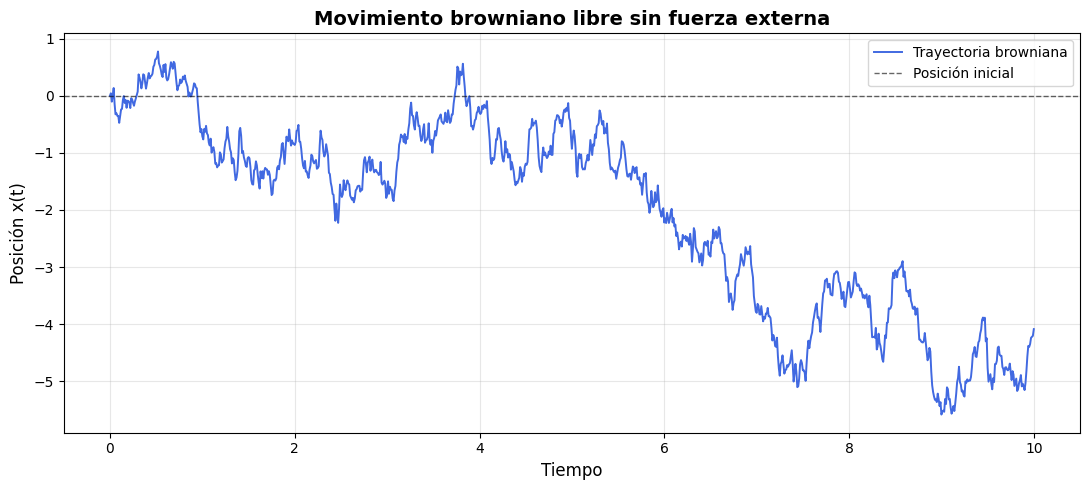

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# LABORATORIO 10
# SIMULACIÓN DEL MOVIMIENTO BROWNIANO SIN FUERZA EXTERNA
# ============================================================

# 1. Parámetros de la simulación

D = 1.0           # Coeficiente de difusión
dt = 0.01         # Paso temporal
T = 10.0          # Tiempo total
x0 = 0.0          # Posición inicial

N = int(T / dt)   # Número de pasos temporales

# Vector de tiempos
t = np.linspace(0, T, N + 1)

# 2. Generador de números aleatorios

rng = np.random.default_rng(seed=42)

# 3. Arreglo para almacenar la posición

x = np.zeros(N + 1)
x[0] = x0

# 4. Simulación del movimiento browniano

for i in range(N):

    # Variable aleatoria gaussiana estándar
    Z = rng.normal(0, 1)

    # Ecuación del movimiento browniano
    x[i + 1] = x[i] + np.sqrt(2 * D * dt) * Z

# 5. Resultados numéricos

print("SIMULACIÓN DEL MOVIMIENTO BROWNIANO")
print("----------------------------------")
print(f"Coeficiente de difusión: {D}")
print(f"Paso temporal: {dt}")
print(f"Tiempo total: {T}")
print(f"Número de pasos: {N}")
print(f"Posición inicial: {x[0]:.4f}")
print(f"Posición final: {x[-1]:.4f}")

# 6. Gráfica de la trayectoria

plt.figure(figsize=(11, 5))

plt.plot(
    t,
    x,
    color="royalblue",
    linewidth=1.4,
    label="Trayectoria browniana"
)

plt.axhline(
    y=x0,
    color="black",
    linestyle="--",
    linewidth=1,
    alpha=0.6,
    label="Posición inicial"
)

plt.xlabel("Tiempo", fontsize=12)
plt.ylabel("Posición x(t)", fontsize=12)

plt.title(
    "Movimiento browniano libre sin fuerza externa",
    fontsize=14,
    fontweight="bold"
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Generator(PCG64)


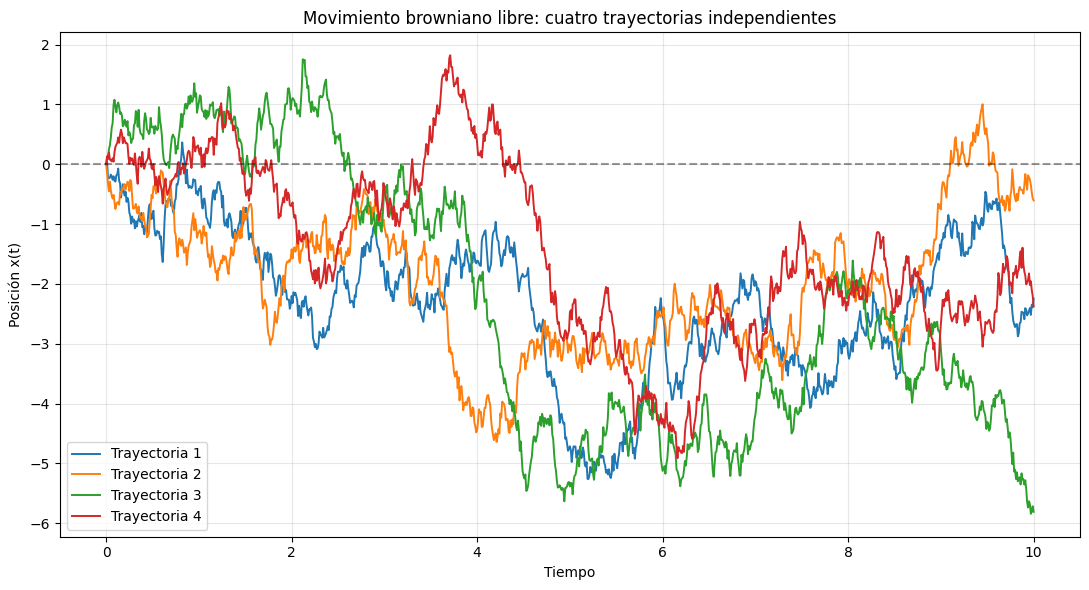

POSICIONES FINALES
Trayectoria 1: x = -2.2470
Trayectoria 2: x = -0.6045
Trayectoria 3: x = -5.8076
Trayectoria 4: x = -2.3757


In [9]:

import numpy as np # importamos las librerias
import matplotlib.pyplot as plt # importamos las librerias

# ============================================================
# LABORATORIO 10
# MOVIMIENTO BROWNIANO SIN FUERZA EXTERNA
# CUATRO TRAYECTORIAS INDEPENDIENTES
# ============================================================

# 1. Parámetros
D = 1.0 # parametro de difusion
dt = 0.01 # incremento temporal
T = 10.0 # limite maximo
x0 = 0.0 # posicion inicial

N = int(T / dt) # numero de pasos temporales
num_trayectorias = 4 # numero de trayectorias a considerar

# Vector de tiempos
t = np.linspace(0, T, N + 1) # vector de tiempos

# 2. Generador aleatorio
rng = np.random.default_rng(seed=42) # generador de numeros aleatorios
print(rng)
# 3. Matriz de posiciones
# Filas: instantes de tiempo
# Columnas: trayectorias

x = np.zeros((N + 1, num_trayectorias))   # creo una matriz de 1000 X 4  10000 DATOS PARA 4 TRAYECTORIAS DISTINTAS.
x[0, :] = x0 # X[0,:] primer valor

# 4. Simulación
for i in range(N):

    # Un número gaussiano independiente por trayectoria
    Z = rng.normal(0, 1, size=num_trayectorias)

    # Actualización browniana
    x[i + 1, :] = x[i, :] + np.sqrt(2 * D * dt) * Z  # x[i+1,:]

# 5. Gráfica
plt.figure(figsize=(11, 6))

for j in range(num_trayectorias):
    plt.plot(
        t,
        x[:, j],
        linewidth=1.4,
        label=f"Trayectoria {j + 1}"
    )

plt.axhline(0, color="black", linestyle="--", alpha=0.4)

plt.xlabel("Tiempo")
plt.ylabel("Posición x(t)")
plt.title("Movimiento browniano libre: cuatro trayectorias independientes")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Posiciones finales
print("POSICIONES FINALES")
for j in range(num_trayectorias):
    print(f"Trayectoria {j + 1}: x = {x[-1, j]:.4f}")


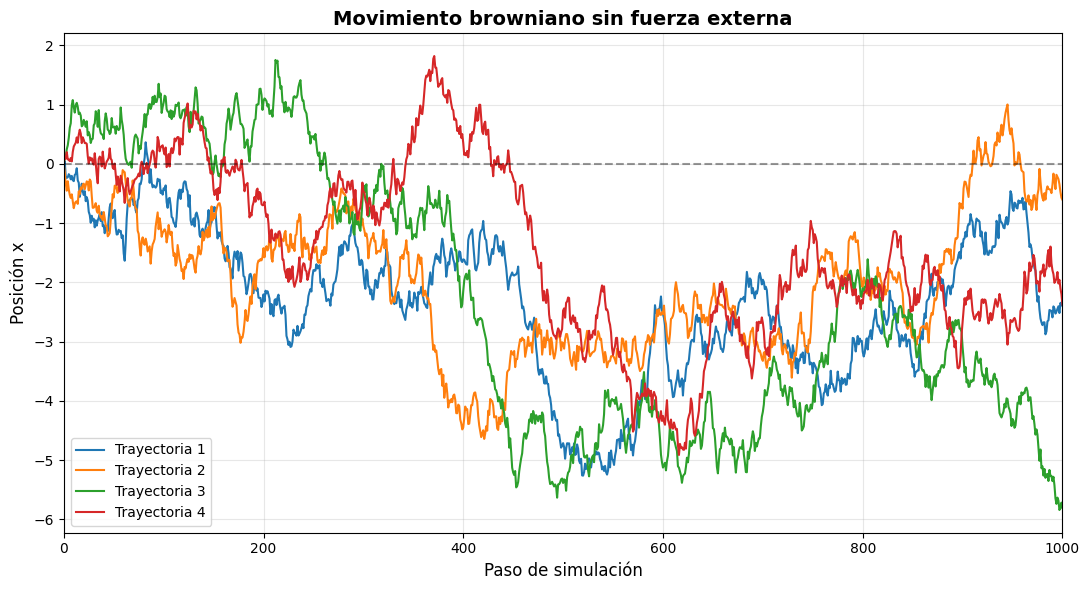

POSICIONES FINALES
Trayectoria 1: -2.2470
Trayectoria 2: -0.6045
Trayectoria 3: -5.8076
Trayectoria 4: -2.3757


In [10]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# LABORATORIO 10
# SIMULACIÓN DEL MOVIMIENTO BROWNIANO SIN FUERZA EXTERNA
# ============================================================

# Parámetros de la simulación
D = 1.0
dt = 0.01
N = 1000
x0 = 0.0
num_trayectorias = 4

# Generador de números aleatorios
rng = np.random.default_rng(seed=42)

# Matriz para almacenar las posiciones
x = np.zeros((N + 1, num_trayectorias))
x[0, :] = x0

# Simulación del movimiento browniano
for i in range(N):

    # Fluctuaciones gaussianas independientes
    Z = rng.normal(0, 1, size=num_trayectorias)

    # Actualización de las posiciones
    x[i + 1, :] = x[i, :] + np.sqrt(2 * D * dt) * Z

# ============================================================
# GRÁFICA DE LAS TRAYECTORIAS
# ============================================================

plt.figure(figsize=(11, 6))

for j in range(num_trayectorias):
    plt.plot(
        np.arange(N + 1),
        x[:, j],
        linewidth=1.5,
        label=f"Trayectoria {j + 1}"
    )

plt.axhline(0, color="black", linestyle="--", alpha=0.4)

plt.xlabel("Paso de simulación", fontsize=12)
plt.ylabel("Posición x", fontsize=12)
plt.title(
    "Movimiento browniano sin fuerza externa",
    fontsize=14,
    fontweight="bold"
)

plt.xlim(0, N)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Resultados
print("POSICIONES FINALES")
for j in range(num_trayectorias):
    print(f"Trayectoria {j + 1}: {x[-1, j]:.4f}")


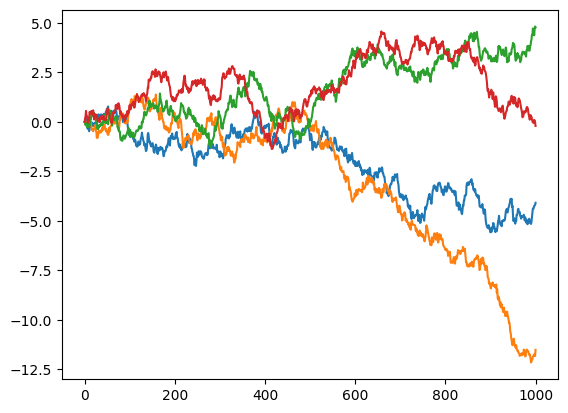

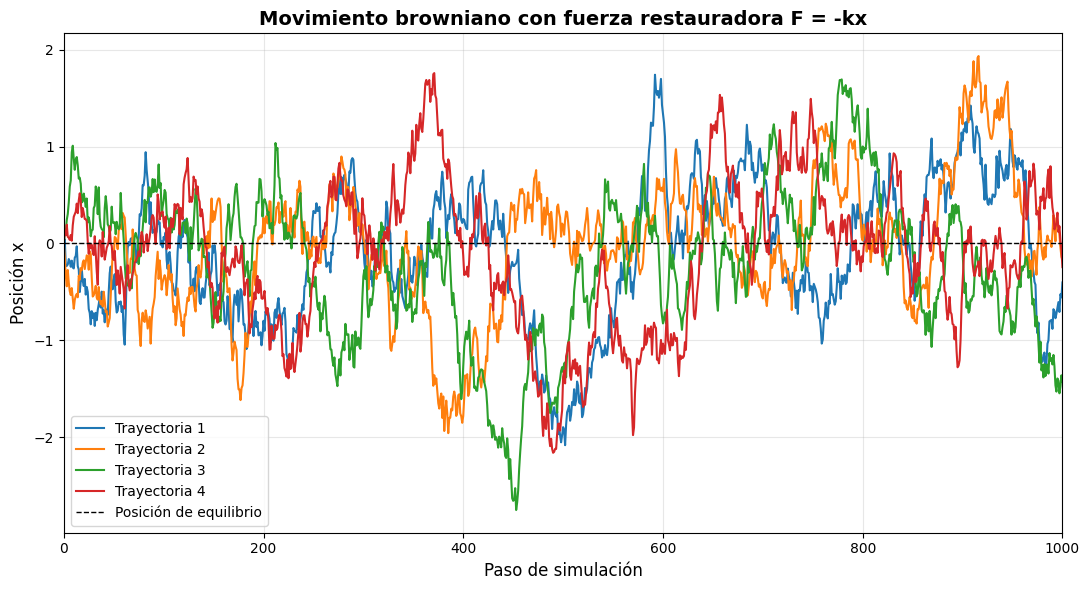

MOVIMIENTO BROWNIANO CON FUERZA EXTERNA
---------------------------------------
Constante del resorte: 2.0
Coeficiente de fricción: 1.0
Coeficiente de difusión: 1.0

POSICIONES FINALES
Trayectoria 1: -0.4024
Trayectoria 2: -0.1698
Trayectoria 3: -1.4262
Trayectoria 4: -0.2443


In [13]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# LABORATORIO 10
# MOVIMIENTO BROWNIANO CON FUERZA EXTERNA F = -kx
# ============================================================

# 1. Parámetros de la simulación

D = 1.0                # Coeficiente de difusión
gamma = 1.0            # Coeficiente de fricción
k = 2.0                # Constante del resorte
dt = 0.01              # Paso temporal
N = 1000               # Número de pasos
x0 = 0.0               # Posición inicial
num_trayectorias = 4

# 2. Generador de números aleatorios

rng = np.random.default_rng(seed=42) # generador de numeros aleatorios la semilla

# 3. Matriz de posiciones

x_resorte = np.zeros((N + 1, num_trayectorias)) # creamos una matriz de 1001 x 4
x_resorte[0, :] = x0 # posicion inicial para las cuatro posiciones, es decir la primera fila.

# 4. Simulación mediante Euler-Maruyama

for i in range(N):

    # Ruido gaussiano independiente
    Z = rng.normal(0, 1, size=num_trayectorias) # generamos 4 numeros aleatorios entre 0,1 esto se guardara en una lista [z1,z2,z3,z4]


    # Fuerza restauradora F = -kx
    fuerza = -k * x_resorte[i, :] # calculamos la fuerza restauradora para cada fila

    # Actualización de las posiciones # aca calculamos la posicion del resorte de cada fila con los distintos ruidos aleatorios z
    x_resorte[i + 1, :] = (
        x_resorte[i, :]
        + (fuerza / gamma) * dt
        + np.sqrt(2 * D * dt) * Z
    )

# ============================================================
# 5. GRÁFICA # aca graficamos todas las distintas tryectorias
# ============================================================

plt.figure(figsize=(11, 6))

for j in range(num_trayectorias):
    plt.plot(
        np.arange(N + 1),
        x_resorte[:, j],
        linewidth=1.5,
        label=f"Trayectoria {j + 1}"
    )

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Posición de equilibrio"
)

plt.xlabel("Paso de simulación", fontsize=12)
plt.ylabel("Posición x", fontsize=12)

plt.title(
    "Movimiento browniano con fuerza restauradora F = -kx",
    fontsize=14,
    fontweight="bold"
)

plt.xlim(0, N)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Resultados

print("MOVIMIENTO BROWNIANO CON FUERZA EXTERNA")
print("---------------------------------------")
print(f"Constante del resorte: {k}")
print(f"Coeficiente de fricción: {gamma}")
print(f"Coeficiente de difusión: {D}")

print("\nPOSICIONES FINALES")
for j in range(num_trayectorias):
    print(f"Trayectoria {j + 1}: {x_resorte[-1, j]:.4f}")


# All trajectories are fluctuating around the zero position, the armonic force tries to keep the position around the cero, meanwhile
# the weiner process generates fluctuations in the particle


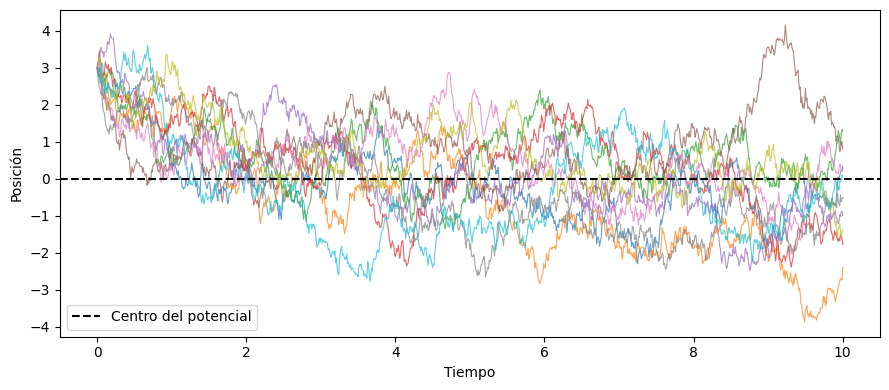

# Con modelos tipo Score

# Dinámica de Langevin con un campo score

Para una densidad de probabilidad $p_\theta(\mathbf{x})$,
definimos el campo score como

$$
\mathbf{s}_\theta(\mathbf{x})
=
\nabla_{\mathbf{x}}\log p_\theta(\mathbf{x}).
$$

Este campo apunta hacia la dirección de máximo crecimiento
local del logaritmo de la densidad.

## Relación entre el score y la fuerza

Para una distribución de Boltzmann,

$$
p_\theta(\mathbf{x})
=
\frac{1}{Z_\theta}
\exp\left[-\frac{U_\theta(\mathbf{x})}{k_BT}\right],
$$

el score es

$$
\mathbf{s}_\theta(\mathbf{x})
=
-\frac{1}{k_BT}\nabla_{\mathbf{x}}U_\theta(\mathbf{x}).
$$

Como la fuerza es $\mathbf{F}_\theta=-\nabla U_\theta$,

$$
\mathbf{F}_\theta(\mathbf{x})
=
k_BT\,\mathbf{s}_\theta(\mathbf{x}).
$$

## Ecuación estocástica

La dinámica sobreamortiguada es

$$
d\mathbf{X}_t
=
\frac{\mathbf{F}_\theta(\mathbf{X}_t)}{\gamma}\,dt
+
\sqrt{2D}\,d\mathbf{W}_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Sustituyendo la fuerza por su expresión en términos del score:

$$
d\mathbf{X}_t
=
D\,\mathbf{s}_\theta(\mathbf{X}_t)\,dt
+
\sqrt{2D}\,d\mathbf{W}_t.
$$

El campo produce un desplazamiento dirigido y el ruido
mantiene las fluctuaciones. Durante esta evolución,
$\theta$ permanece fijo.

## Incrementos de Wiener

En $d$ dimensiones,

$$
\Delta\mathbf{W}_n
=
\sqrt{\Delta t}\,\boldsymbol{\epsilon}_n,
\qquad
\boldsymbol{\epsilon}_n\sim\mathcal{N}(\mathbf{0},I_d),
$$

con nuevos vectores independientes en cada paso.

## Actualización numérica

La aproximación de Euler–Maruyama es

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
D\,\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2D\Delta t}\,\boldsymbol{\epsilon}_n.
$$

En unidades donde $D=1$:

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2\Delta t}\,\boldsymbol{\epsilon}_n.
$$

Con el score exacto y condiciones adecuadas de convergencia,
la dinámica continua reproduce $p_\theta$ a tiempos largos.
La actualización numérica introduce un error de discretización.

## Ejemplo: distribución gaussiana

Para una gaussiana con media $\boldsymbol{\mu}$ y
covarianza $vI_d$,

$$
\mathbf{s}(\mathbf{x})
=
-\frac{\mathbf{x}-\boldsymbol{\mu}}{v}.
$$



In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Gaussiana objetivo
mu = 0.0
varianza = 1.0

def densidad(x):
    return np.exp(-(x - mu)**2 / (2 * varianza)) / np.sqrt(
        2 * np.pi * varianza
    )

def score(x):
    return -(x - mu) / varianza



In [16]:

import numpy as np

# Generador de números aleatorios
rng = np.random.default_rng(42)

# Parámetros de la simulación
n_trayectorias = 200
n_pasos = 1_000
dt = 0.01

# Todas las trayectorias comienzan en x = 0
# Se incluye la posición inicial y los 1000 pasos
x = np.zeros((n_trayectorias, n_pasos + 1))

# Vector de tiempos
t = np.arange(n_pasos + 1) * dt

# Verificación de dimensiones
print("Dimensiones de x:", x.shape)
print("Dimensiones de t:", t.shape)
print("Tiempo total:", t[-1])


Dimensiones de x: (200, 1001)
Dimensiones de t: (1001,)
Tiempo total: 10.0


In [17]:
x = np.zeros((n_trayectorias, n_pasos + 1))

# Todas las trayectorias comienzan en cero
x[:, 0] = 0.0

for k in range(n_trayectorias):
    for j in range(n_pasos):
        ruido = rng.normal()

        x[k, j + 1] = (
            x[k, j]
            + dt * score(x[k, j])
            + np.sqrt(2 * dt) * ruido
        )

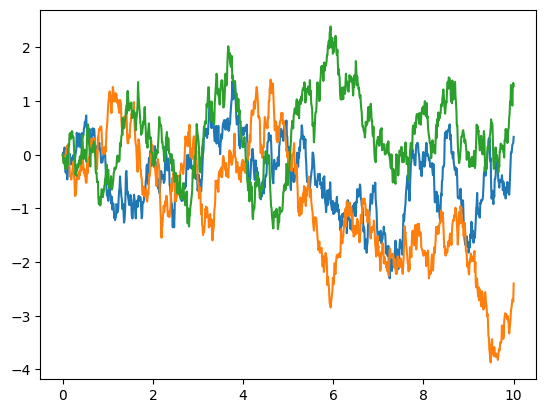

In [19]:
plt.plot(t, x[0])
plt.plot(t, x[1])
plt.plot(t, x[2])

In [20]:
x=np.concat(x)

Media de las muestras:    -0.0092
Varianza de las muestras: 0.9434
Varianza teórica discreta: 1.0050


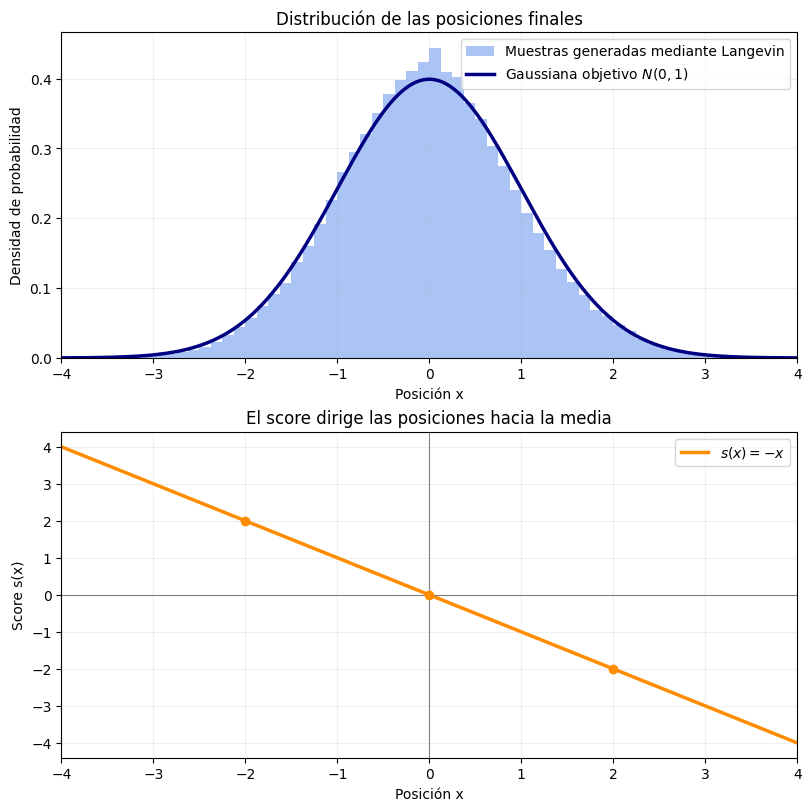

In [21]:
# Resultados
print(f"Media de las muestras:    {np.mean(x):.4f}")
print(f"Varianza de las muestras: {np.var(x):.4f}")

# Varianza estacionaria de la actualización discreta
varianza_discreta = varianza / (1 - dt / (2 * varianza))
print(f"Varianza teórica discreta: {varianza_discreta:.4f}")


# Gráficas
eje = np.linspace(-4, 4, 600)

fig, axes = plt.subplots(
    2, 1, figsize=(8, 8), constrained_layout=True
)

# Densidad objetivo e histograma de posiciones finales
axes[0].hist(
    x,
    bins=np.linspace(-4, 4, 65),
    density=True,
    color="cornflowerblue",
    alpha=0.55,
    label="Muestras generadas mediante Langevin"
)

axes[0].plot(
    eje,
    densidad(eje),
    color="navy",
    linewidth=2.5,
    label=r"Gaussiana objetivo ${N}(0,1)$"
)

axes[0].set(
    title="Distribución de las posiciones finales",
    xlabel="Posición x",
    ylabel="Densidad de probabilidad",
    xlim=(-4, 4)
)
axes[0].legend()
axes[0].grid(alpha=0.2)

# Campo score
axes[1].plot(
    eje,
    score(eje),
    color="darkorange",
    linewidth=2.5,
    label=r"$s(x) = -x$"
)

axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].axvline(mu, color="gray", linewidth=0.8)

axes[1].scatter(
    [-2, 0, 2],
    score(np.array([-2, 0, 2])),
    color="darkorange",
    zorder=3
)

axes[1].set(
    title="El score dirige las posiciones hacia la media",
    xlabel="Posición x",
    ylabel="Score s(x)",
    xlim=(-4, 4)
)
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.show()

Simule la dinámica de Langevin de partículas inicialmente distribuidas al azar en el plano, utilizando el campo score de una gaussiana de media \((0,0)\) y covarianza identidad. Visualice el campo y cinco trayectorias. Compare la distribución final de las partículas con la gaussiana objetivo y calcule su media y covarianza.

MEDIA OBJETIVO:
[0. 0.]

MEDIA ESTIMADA:
[-0.00655326  0.014428  ]

COVARIANZA OBJETIVO:
[[1. 0.]
 [0. 1.]]

COVARIANZA ESTIMADA:
[[ 1.05090052 -0.01344069]
 [-0.01344069  0.99341834]]


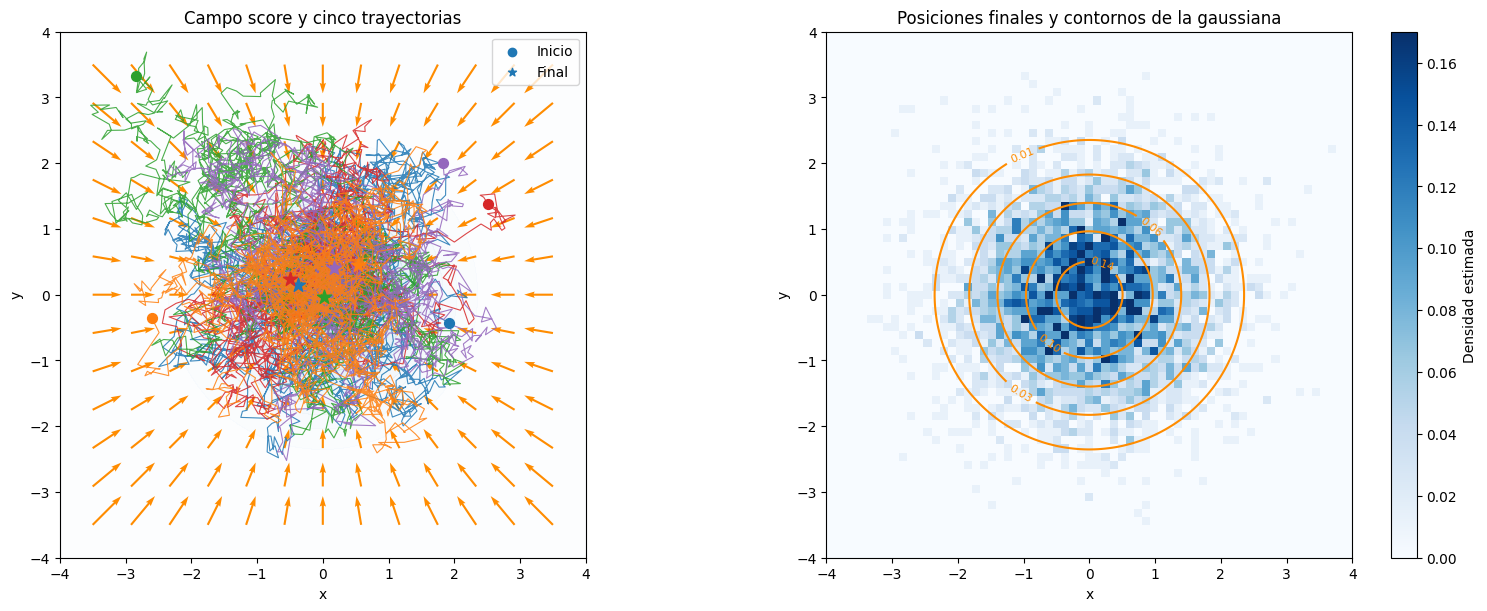

In [22]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# LABORATORIO 10
# DINÁMICA DE LANGEVIN EN DOS DIMENSIONES
# GAUSSIANA OBJETIVO N((0,0), I)
# ============================================================

# 1. Parámetros
rng = np.random.default_rng(42) # semilla aleatoria

n_particulas = 5000 # simulamos 5000 particulas
n_pasos = 2000 # 2000 pasos
dt = 0.01 # incrementos temporales
D = 1.0 # coeficiente de difusion

mu = np.array([0.0, 0.0]) # media
Sigma = np.eye(2) # tenemos una distribucion bidimensional por lo tanto usamos la covarianza

# 2. Densidad gaussiana bidimensional
def densidad_2d(x, y):
    return np.exp(-(x**2 + y**2) / 2) / (2 * np.pi) # esta es la distribucion gaussiana

# 3. Campo score
def score_2d(posiciones): # el campo score que redirigira nuestras particulas hacia el centro
    return -(posiciones - mu)

# 4. Posiciones iniciales aleatorias
# Uniformemente distribuidas en el plano [-3.5, 3.5]^2
posiciones = rng.uniform(
    -3.5, 3.5, size=(n_particulas, 2) # posiciones aleatorias
)

# Guardar cinco trayectorias completas
indices = np.arange(5)

trayectorias = np.zeros((5, n_pasos + 1, 2))
trayectorias[:, 0, :] = posiciones[indices]

# 5. Simulación de Langevin
for j in range(n_pasos):

    ruido = rng.normal(size=(n_particulas, 2))

    posiciones = (
        posiciones
        + D * score_2d(posiciones) * dt
        + np.sqrt(2 * D * dt) * ruido
    )

    trayectorias[:, j + 1, :] = posiciones[indices]

# 6. Estadísticas finales
media_final = np.mean(posiciones, axis=0)
covarianza_final = np.cov(posiciones, rowvar=False)

print("MEDIA OBJETIVO:")
print(mu)

print("\nMEDIA ESTIMADA:")
print(media_final)

print("\nCOVARIANZA OBJETIVO:")
print(Sigma)

print("\nCOVARIANZA ESTIMADA:")
print(covarianza_final)

# ============================================================
# 7. VISUALIZACIONES
# ============================================================

fig, axes = plt.subplots(
    1, 2, figsize=(15, 6), constrained_layout=True
)

# Malla para el campo y la densidad
eje = np.linspace(-4, 4, 150)
X, Y = np.meshgrid(eje, eje)

P = densidad_2d(X, Y)

# ------------------------------------------------------------
# GRÁFICA IZQUIERDA: SCORE Y CINCO TRAYECTORIAS
# ------------------------------------------------------------

ax = axes[0]

# Contornos suaves de la gaussiana
ax.contourf(
    X, Y, P,
    levels=15,
    cmap="Blues",
    alpha=0.18
)

# Campo vectorial score
eje_flechas = np.linspace(-3.5, 3.5, 13)
XF, YF = np.meshgrid(eje_flechas, eje_flechas)

SX = -XF
SY = -YF

ax.quiver(
    XF, YF, SX, SY,
    color="darkorange",
    angles="xy",
    scale_units="xy",
    scale=8,
    width=0.004
)

# Cinco trayectorias independientes
colores = ["tab:blue", "tab:red", "tab:green",
           "tab:purple", "tab:orange"]

for i in range(5):
    ax.plot(
        trayectorias[i, :, 0],
        trayectorias[i, :, 1],
        color=colores[i],
        linewidth=0.8,
        alpha=0.85
    )

    # Posición inicial
    ax.scatter(
        trayectorias[i, 0, 0],
        trayectorias[i, 0, 1],
        color=colores[i],
        s=50,
        zorder=5
    )

    # Posición final
    ax.scatter(
        trayectorias[i, -1, 0],
        trayectorias[i, -1, 1],
        color=colores[i],
        marker="*",
        s=110,
        zorder=6
    )

ax.scatter([], [], color="tab:blue", label="Inicio")
ax.scatter([], [], color="tab:blue", marker="*", label="Final")

ax.set(
    title="Campo score y cinco trayectorias",
    xlabel="x",
    ylabel="y",
    xlim=(-4, 4),
    ylim=(-4, 4)
)

ax.set_aspect("equal")
ax.legend()

# ------------------------------------------------------------
# GRÁFICA DERECHA: DISTRIBUCIÓN FINAL
# ------------------------------------------------------------

ax = axes[1]

# Histograma bidimensional de posiciones finales
hist = ax.hist2d(
    posiciones[:, 0],
    posiciones[:, 1],
    bins=65,
    range=[[-4, 4], [-4, 4]],
    density=True,
    cmap="Blues",
    vmin=0,
    vmax=0.17
)

# Contornos de la distribución objetivo
niveles = [0.01, 0.03, 0.06, 0.10, 0.14]

contornos = ax.contour(
    X, Y, P,
    levels=niveles,
    colors="darkorange",
    linewidths=1.5
)

ax.clabel(
    contornos,
    inline=True,
    fontsize=8,
    fmt="%.2f"
)

ax.set(
    title="Posiciones finales y contornos de la gaussiana",
    xlabel="x",
    ylabel="y",
    xlim=(-4, 4),
    ylim=(-4, 4)
)

ax.set_aspect("equal")

fig.colorbar(
    hist[3],
    ax=ax,
    label="Densidad estimada"
)

plt.show()



## Conclusiones

En este laboratorio se estudió el movimiento browniano mediante la ecuación de Langevin, permitiendo comprender cómo la evolución de una partícula está determinada por la combinación de fuerzas deterministas y fluctuaciones aleatorias. A partir de las simulaciones realizadas, se obtuvieron las siguientes conclusiones:

1. **Movimiento browniano libre:** Se observó que, en ausencia de fuerzas externas, las partículas describen trayectorias irregulares debido al ruido térmico. Aunque el desplazamiento promedio tiende a cero al considerar muchas realizaciones, las partículas individuales pueden alejarse progresivamente de su posición inicial, característica fundamental de los procesos difusivos.

2. **Efecto de una fuerza restauradora:** Al introducir una fuerza de la forma $F=-kx$, las partículas presentaron fluctuaciones alrededor de la posición de equilibrio. A diferencia del movimiento browniano libre, la fuerza restauradora limita la dispersión de las posiciones y permite alcanzar una distribución estacionaria con varianza finita.

3. **Interpretación del campo score:** Se comprendió que el score, definido como $s(x)=\nabla_x\log p(x)$, proporciona información sobre la dirección en la que aumenta la densidad de probabilidad. Para una distribución gaussiana centrada en el origen, este campo apunta hacia el centro, desempeñando un papel equivalente al de una fuerza restauradora.

4. **Generación de distribuciones mediante Langevin:** Las simulaciones mostraron cómo es posible utilizar un campo score para dirigir la evolución estocástica de un conjunto de partículas hacia una distribución de probabilidad objetivo. En el caso gaussiano, las posiciones finales se aproximan a la distribución esperada, como puede comprobarse mediante histogramas y curvas de densidad.

5. **Extensión a dos dimensiones:** Al simular partículas en el plano, se observó que el campo score de una gaussiana bidimensional dirige el movimiento hacia la región central, mientras que el ruido mantiene las fluctuaciones en ambas coordenadas. La comparación entre la distribución final y los contornos teóricos permite visualizar el comportamiento estadístico del sistema.

6. **Importancia de la media y la covarianza:** El cálculo de estas magnitudes permite evaluar cuantitativamente la aproximación a la distribución objetivo. Para la gaussiana bidimensional estudiada, se espera una media cercana a $(0,0)$ y una matriz de covarianza próxima a la identidad. Las diferencias observadas pueden atribuirse al número finito de partículas y al error de discretización del método numérico.

7. **Alcance del método numérico:** El método de Euler–Maruyama permitió implementar de manera sencilla las ecuaciones diferenciales estocásticas. Sin embargo, se reconoció que el tamaño del paso temporal influye en la precisión de los resultados, por lo que debe elegirse adecuadamente para reproducir las propiedades estadísticas del sistema.

### Conclusión general

El laboratorio permitió establecer una conexión entre el movimiento browniano, la mecánica estadística y los modelos generativos basados en score. El resultado más importante es que una distribución de probabilidad puede utilizarse para construir un campo que, combinado con fluctuaciones aleatorias, genera una dinámica cuya distribución estacionaria se aproxima a la distribución objetivo. Esta idea constituye una base conceptual para comprender métodos modernos de muestreo y generación de datos mediante procesos estocásticos.
